# Energy commodity risk model: VaR and Expected Shortfall for Henry Hub natural gas

**Question:** If I hold a long position in natural gas, how much could I lose in one day, and can I trust that number?

I estimate 1-day **Value at Risk (VaR)** and **Expected Shortfall (ES)** at 95% and 99% using three approaches: historical simulation, parametric (normal and Student-t) and Monte Carlo. Then I **backtest** each one: every day I forecast tomorrow's VaR using only past data, count how often the real loss exceeds it, and test those breaches with the Kupiec and Christoffersen tests.

The calculations live in the `src/` folder. This notebook runs them and shows the results.

In [1]:
import sys
sys.path.append("..")  # lets the notebook import the src/ folder

import numpy as np
import pandas as pd
from scipy import stats

from src import data, var_models as vm, backtest, plotting

pd.set_option("display.float_format", "{:.4f}".format)

## 1. Data

Henry Hub natural gas spot price (US$/MMBtu), daily, from FRED series [DHHNGSP](https://fred.stlouisfed.org/series/DHHNGSP), which republishes U.S. Energy Information Administration (EIA) data. It is saved in `data/henry_hub_daily.csv`, so the notebook runs offline. To refresh it, run `data.download_prices()`.

The series starts in 1997, but before 2008 about half the days are missing. A return across a gap would really be a multi-day return, so I start in January 2008.

In [2]:
prices = data.load_prices()
returns = data.log_returns(prices)

print(f"Prices:  {prices.index[0]:%d %b %Y} to {prices.index[-1]:%d %b %Y}, {len(prices):,} days")
print(f"Returns: {len(returns):,} daily log returns")
print(f"Lowest price ${prices.min():.2f} ({prices.idxmin():%b %Y}), highest ${prices.max():.2f} ({prices.idxmax():%b %Y})")

Prices:  02 Jan 2008 to 20 Oct 2026, 4,724 days
Returns: 4,723 daily log returns
Lowest price $1.21 (Nov 2024), highest $30.72 (Jan 2026)


Log return: $r_t = \ln(P_t / P_{t-1})$. I use log returns because they add up over time and are the standard input for VaR models.

Before choosing a model, I check whether the returns look normal. A normal distribution has skewness 0 and excess kurtosis 0.

In [3]:
summary = pd.Series({
    "Mean daily return": returns.mean(),
    "Daily volatility (std)": returns.std(),
    "Annualised volatility": returns.std() * np.sqrt(252),
    "Skewness": returns.skew(),
    "Excess kurtosis": returns.kurt(),
    "Worst day": returns.min(),
    "Best day": returns.max(),
})
jb_stat, jb_p = stats.jarque_bera(returns)
print(summary.to_string())
print(f"\nJarque-Bera normality test: statistic = {jb_stat:,.0f}, p-value = {jb_p:.3g}")
print("\nLargest daily losses:")
print(returns.nsmallest(5).to_string())

Mean daily return         -0.0002
Daily volatility (std)     0.0718
Annualised volatility      1.1393
Skewness                   1.1575
Excess kurtosis          113.3342
Worst day                 -1.4016
Best day                   1.4328

Jarque-Bera normality test: statistic = 2,523,366, p-value = 0

Largest daily losses:
observation_date
2024-01-16   -1.4016
2021-02-18   -1.0251
2025-01-21   -0.8069
2026-01-28   -0.6100
2021-02-19   -0.5457


The excess kurtosis is very large and the Jarque-Bera test rejects normality decisively. Henry Hub spot prices jump during cold snaps (Winter Storm Uri in February 2021, the January 2024 freeze), and when the weather passes they collapse just as fast. That matters for a long position: the worst losses come the day after a spike. These fat tails are why I compare the normal model with a Student-t and with methods that do not assume a distribution.

## 2. Today's VaR and ES

All four methods, using the latest 500 trading days (about two years). I quote VaR and ES as a positive loss, as a fraction of the position, and in dollars for a $1 million long position.

In [4]:
WINDOW = 500
POSITION = 1_000_000
past = returns.iloc[-WINDOW:].to_numpy()

# Inputs for the parametric t and the Monte Carlo model
t_params = vm.fit_student_t(past)
sigma = vm.ewma_volatility(returns.to_numpy())          # EWMA volatility forecasts
z = returns.to_numpy()[1:] / sigma[:-1]                   # standardised returns
shock_params = vm.fit_student_t(z[-WINDOW:])
rng = np.random.default_rng(42)

rows = []
for alpha in (0.95, 0.99):
    results = {
        "Historical": vm.historical_var_es(past, alpha),
        "Normal": vm.normal_var_es(past, alpha),
        "Student-t": vm.student_t_var_es(*t_params, alpha),
        "Monte Carlo (EWMA-t)": vm.monte_carlo_var_es(sigma[-1], shock_params, alpha, rng=rng),
    }
    for method, (var, es) in results.items():
        rows.append({"Level": f"{alpha:.0%}", "Method": method, "VaR": var, "ES": es,
                     "VaR on $1m": var * POSITION, "ES on $1m": es * POSITION})

today = pd.DataFrame(rows)
print(f"Forecast for the trading day after {returns.index[-1]:%d %b %Y}")
print(f"Student-t fitted to raw returns: df = {t_params[0]:.2f}")
print(f"Today's EWMA daily volatility: {sigma[-1]:.2%}  vs  500-day standard deviation: {past.std():.2%}")
today.style.format({"VaR": "{:.2%}", "ES": "{:.2%}", "VaR on $1m": "${:,.0f}", "ES on $1m": "${:,.0f}"}).hide(axis="index")

Forecast for the trading day after 20 Oct 2026
Student-t fitted to raw returns: df = 2.05
Today's EWMA daily volatility: 3.20%  vs  500-day standard deviation: 11.82%


Level,Method,VaR,ES,VaR on $1m,ES on $1m
95%,Historical,10.92%,25.51%,"$109,199","$255,111"
95%,Normal,19.39%,24.34%,"$193,925","$243,362"
95%,Student-t,10.31%,21.35%,"$103,062","$213,467"
95%,Monte Carlo (EWMA-t),4.99%,8.91%,"$49,886","$89,103"
99%,Historical,34.96%,52.75%,"$349,622","$527,505"
99%,Normal,27.46%,31.46%,"$274,553","$314,644"
99%,Student-t,24.25%,47.93%,"$242,536","$479,278"
99%,Monte Carlo (EWMA-t),10.86%,17.84%,"$108,577","$178,441"


The methods disagree a lot. Historical, normal and Student-t all look at the last two years equally, and those two years include the January 2026 price spike. The Monte Carlo model uses EWMA volatility, which gives recent days more weight. The market has been calm for months, so its VaR is much lower today. Which approach is right? The backtest answers that.

**How the Monte Carlo model works:** each day I simulate 10,000 possible returns for tomorrow as $\sigma_t \cdot z$. Here $\sigma_t$ is the RiskMetrics EWMA volatility forecast ($\lambda = 0.94$), and $z$ is a fat-tailed shock drawn from a Student-t fitted to past standardised returns $r_t / \sigma_t$. VaR is the 1st or 5th percentile of the simulated returns, and ES is the average of the simulated returns beyond it.

## 3. Backtest

Every day from January 2010, each model forecasts the next day's VaR and ES using only the previous 500 returns. The Student-t parameters are re-estimated every 21 trading days (about monthly) to keep the run time short. This takes about half a minute.

In [5]:
forecasts = backtest.rolling_forecasts(returns, window=WINDOW)
print(f"Backtest: {forecasts.index[0]:%d %b %Y} to {forecasts.index[-1]:%d %b %Y}, {len(forecasts):,} days")

Backtest: 30 Dec 2009 to 20 Oct 2026, 4,223 days


A **breach** is a day when the loss is bigger than the forecast VaR. A 99% VaR should be breached on about 1% of days, and the breaches should be scattered, not clustered.

- **Kupiec POF test:** is the number of breaches consistent with 1% (or 5%)? H0: breach probability = 1 − α.
- **Christoffersen independence test:** are breaches independent from one day to the next? Clustering means the model reacts too slowly when volatility changes.
- **Conditional coverage:** both tests combined (χ² with 2 degrees of freedom).
- **Avg loss on breach / avg ES:** on breach days, the real average loss divided by the average ES forecast. Close to 1.0 means ES was about right; above 1.0 means the tail was worse than the model expected.

A p-value below 0.05 means I reject the model at the 5% significance level.

In [6]:
results = backtest.backtest_table(forecasts)
results.to_csv("../results/backtest_results.csv", index=False)
results.style.format({
    "Breach rate": "{:.2%}", "Kupiec p": "{:.3f}", "Christoffersen ind. p": "{:.3f}",
    "Cond. coverage p": "{:.3f}", "Avg loss on breach / avg ES": "{:.2f}",
}).hide(axis="index")

Level,Method,Days,Expected breaches,Actual breaches,Breach rate,Kupiec p,Christoffersen ind. p,Cond. coverage p,Avg loss on breach / avg ES
95%,Historical,4223,211,223,5.28%,0.407,0.000,0.000,1.04
95%,Normal,4223,211,135,3.20%,0.000,0.000,0.000,1.48
95%,Student-t,4223,211,256,6.06%,0.002,0.000,0.000,1.05
95%,Monte Carlo (EWMA-t),4223,211,239,5.66%,0.054,0.023,0.012,0.85
99%,Historical,4223,42,53,1.26%,0.109,0.000,0.000,1.04
99%,Normal,4223,42,55,1.30%,0.059,0.000,0.000,1.72
99%,Student-t,4223,42,51,1.21%,0.189,0.000,0.000,1.19
99%,Monte Carlo (EWMA-t),4223,42,37,0.88%,0.409,0.419,0.512,0.76


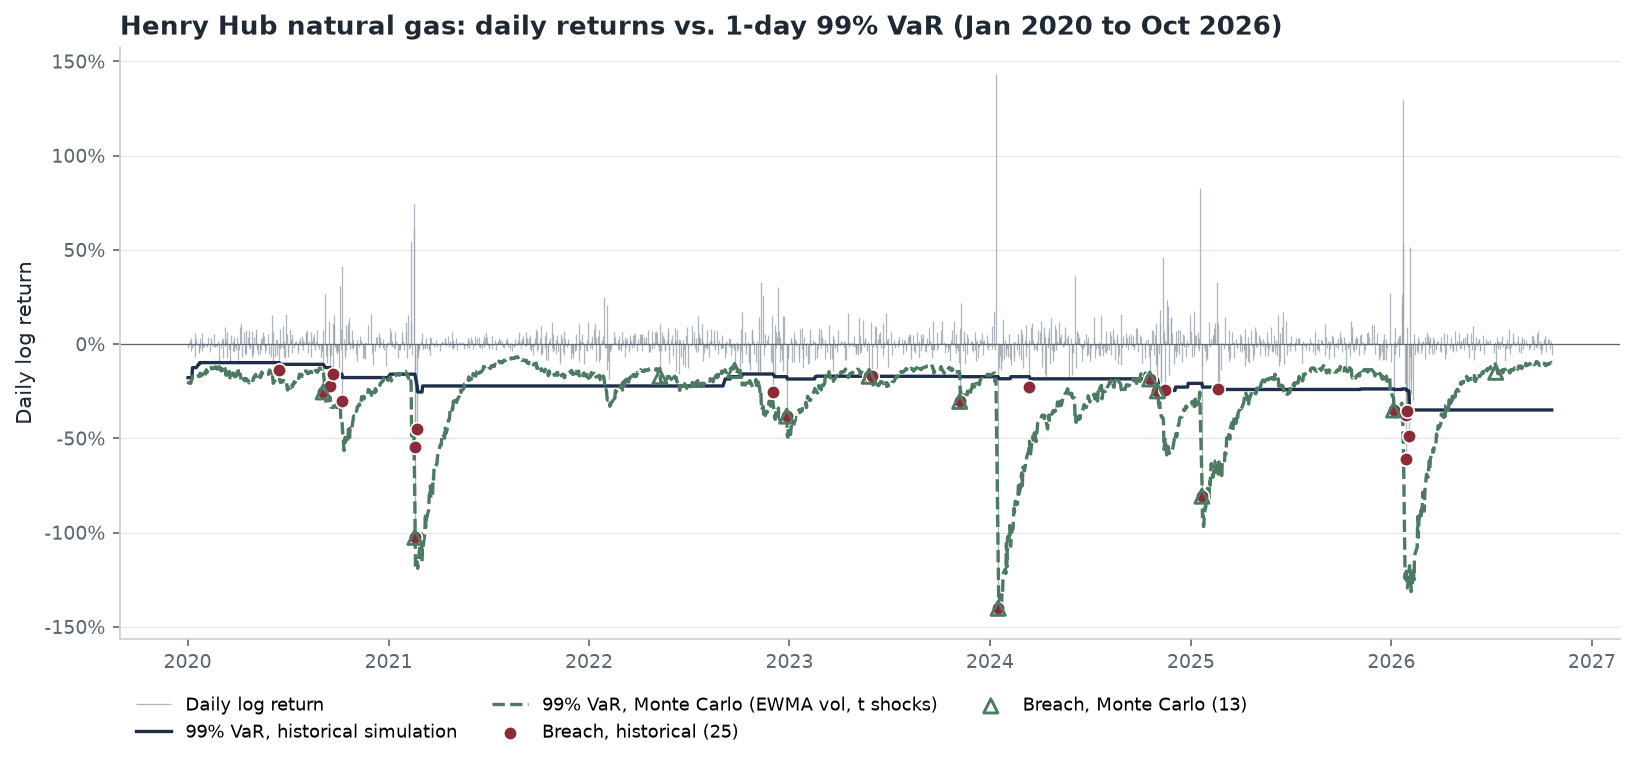

In [7]:
fig, ax = plotting.plot_var_breaches(forecasts, level=99, start="2020-01-01",
                                     path="../images/var_breaches_99.png")

## 4. What the backtest says

- **The normal model gets the tail wrong.** At 95% it overstates VaR (too few breaches: the outliers inflate the standard deviation). At 99% the breach count is borderline, but its ES is the worst of all: on breach days the real loss was about 1.7 times the ES it predicted. Assuming normality hides how bad the bad days are.
- **Historical simulation and Student-t get roughly the right number of breaches at 99%** and pass Kupiec. But they **fail Christoffersen's independence test**: their breaches come in bunches, because a fixed two-year window reacts slowly. In the chart, the historical VaR line barely moves when a cold snap hits, so it is breached several days in a row.
- **Monte Carlo with EWMA volatility and t shocks is the only model that passes all three tests at 99%.** Because its volatility reacts within days, it widens quickly after a shock and narrows again when markets calm down. Its ES ratio below 1 means its ES is conservative: real tail losses were smaller than it predicted.
- At 95%, every model fails at least one test. Even the best (Monte Carlo) shows some clustering, which points to the next improvement: a GARCH model or a regime-switching model.

See the README for limitations and next steps.